In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def generate_directions(self, E: float) -> np.ndarray:
        """Разыгрывает начальные направления фотонов для события с энергией E (МэВ)."""
        N = int(self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        
        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta
        return np.column_stack((nx, ny, nz))


class Detector:
    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.1, a: float = 0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)
        self.pmt_coords = self._generate_pmt_positions()
        
    def _generate_pmt_positions(self) -> np.ndarray:
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R * (1 - 2 * indices / self.N)
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        return np.column_stack((x, y, z))

    def generate_photoelectrons(self, n_hits: int | np.ndarray = 1) -> int | np.ndarray:
        return np.random.poisson(lam=self.a * n_hits)

    def detect_photons(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        
        hit_points = origin + t[:, None] * directions
        
        hits_per_pmt = np.zeros(self.N, dtype=int)
        for i, pmt_center in enumerate(self.pmt_coords):
            distances = np.linalg.norm(hit_points - pmt_center, axis=1)
            hits_per_pmt[i] = np.sum(distances <= self.r)
            
        pe_per_pmt = self.generate_photoelectrons(hits_per_pmt)
        return pe_per_pmt


detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
source = Source(Y=10000)

def simulate_events(E: float, origin: np.ndarray, n_events: int = 1000) -> np.ndarray:
    """Моделирует n_events событий с энергией E в точке origin."""
    charges = []
    for _ in range(n_events):
        dirs = source.generate_directions(E)
        pe_counts = detector.detect_photons(origin, dirs)
        charges.append(np.sum(pe_counts))
    return np.array(charges)

Средний собранный заряд: 125.33 ф.э.
Стандартное отклонение (ширина): 13.49 ф.э.


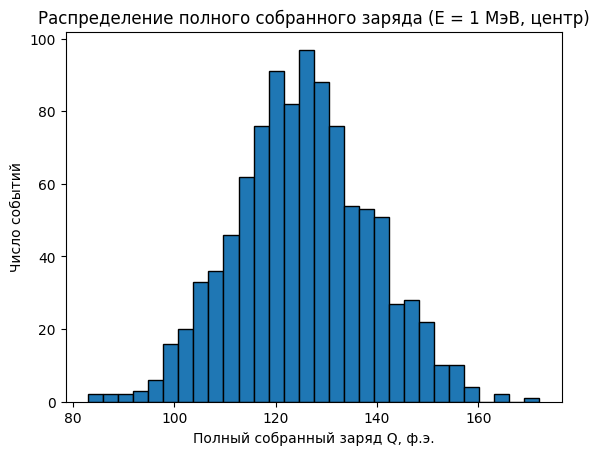

In [2]:
origin_center = np.array([0.0, 0.0, 0.0])

# Моделируем 1000 событий с энергией 1 МэВ в центре
charges_1mev = simulate_events(E=1.0, origin=origin_center, n_events=1000)

print(f"Средний собранный заряд: {np.mean(charges_1mev):.2f} ф.э.")
print(f"Стандартное отклонение (ширина): {np.std(charges_1mev):.2f} ф.э.")

plt.hist(charges_1mev, bins=30, edgecolor='black')
plt.xlabel('Полный собранный заряд Q, ф.э.')
plt.ylabel('Число событий')
plt.title('Распределение полного собранного заряда (E = 1 МэВ, центр)')
plt.show()

E = 0.2 МэВ | <Q> центр = 25.0, <Q> (z=1м) = 25.1 | Отн. ширина (центр) = 0.243
E = 0.5 МэВ | <Q> центр = 62.2, <Q> (z=1м) = 62.4 | Отн. ширина (центр) = 0.155
E = 0.7 МэВ | <Q> центр = 87.3, <Q> (z=1м) = 86.8 | Отн. ширина (центр) = 0.133
E = 1.0 МэВ | <Q> центр = 125.3, <Q> (z=1м) = 125.1 | Отн. ширина (центр) = 0.109
E = 1.5 МэВ | <Q> центр = 187.1, <Q> (z=1м) = 186.4 | Отн. ширина (центр) = 0.086
E = 2.0 МэВ | <Q> центр = 251.0, <Q> (z=1м) = 249.1 | Отн. ширина (центр) = 0.073
E = 3.0 МэВ | <Q> центр = 375.6, <Q> (z=1м) = 374.8 | Отн. ширина (центр) = 0.062


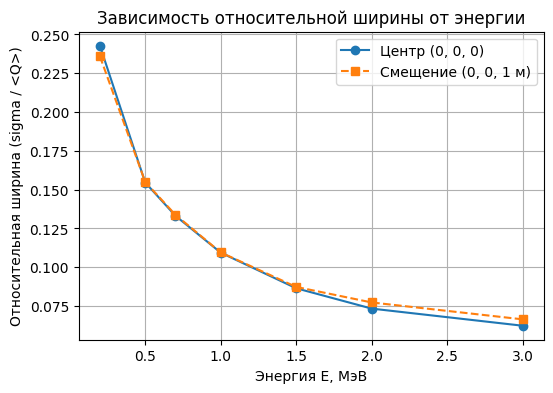

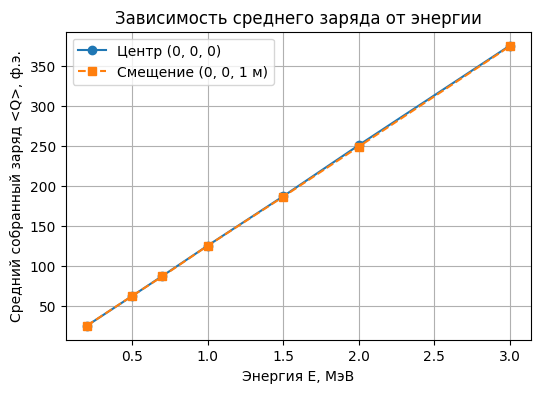

In [3]:
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
origin_shifted = np.array([0.0, 0.0, 1.0])

mean_center = []
rel_width_center = []

mean_shifted = []
rel_width_shifted = []

for E in energies:
    # 1. В центре детектора (0, 0, 0)
    q_center = simulate_events(E=E, origin=origin_center, n_events=1000)
    mean_c = np.mean(q_center)
    std_c = np.std(q_center)
    
    mean_center.append(mean_c)
    rel_width_center.append(std_c / mean_c) # Относительная ширина = sigma / <Q>
    
    # 2. Со смещением на 1 м по оси z (0, 0, 1)
    q_shifted = simulate_events(E=E, origin=origin_shifted, n_events=1000)
    mean_s = np.mean(q_shifted)
    std_s = np.std(q_shifted)
    
    mean_shifted.append(mean_s)
    rel_width_shifted.append(std_s / mean_s)
    
    print(f"E = {E} МэВ | <Q> центр = {mean_c:.1f}, <Q> (z=1м) = {mean_s:.1f} | "
          f"Отн. ширина (центр) = {std_c / mean_c:.3f}")

# График 1: Зависимость относительной ширины от энергии
plt.figure(figsize=(6, 4))
plt.plot(energies, rel_width_center, 'o-', label='Центр (0, 0, 0)')
plt.plot(energies, rel_width_shifted, 's--', label='Смещение (0, 0, 1 м)')
plt.xlabel('Энергия E, МэВ')
plt.ylabel('Относительная ширина (sigma / <Q>)')
plt.title('Зависимость относительной ширины от энергии')
plt.legend()
plt.grid(True)
plt.show()

# График 2: Сравнение среднего заряда в центре и при смещении z = 1 м
plt.figure(figsize=(6, 4))
plt.plot(energies, mean_center, 'o-', label='Центр (0, 0, 0)')
plt.plot(energies, mean_shifted, 's--', label='Смещение (0, 0, 1 м)')
plt.xlabel('Энергия E, МэВ')
plt.ylabel('Средний собранный заряд <Q>, ф.э.')
plt.title('Зависимость среднего заряда от энергии')
plt.legend()
plt.grid(True)
plt.show()